# Práctica: Reconocimiento de Dígitos Manuscritos con Adaline (NumPy Puro)

**Materia:** Redes Neuronales / Internet de las Cosas  
**Ejercicio:** Inciso A — Implementación de Adaline sin Frameworks Especializados  
**Autor:** Práctica Académica Reproducible  
**Semilla de Reproducibilidad:** 42  

---

## 1. Introducción y Objetivo
El objetivo de este cuaderno es implementar desde cero el modelo **Adaline** (*ADAptive LInear NEuron*, Widrow & Hoff, 1960) utilizando exclusivamente **Python y NumPy** para la computación matemática y **Matplotlib** para la visualización gráfica.

### Aspectos Clave de la Arquitectura:
1. **Sin frameworks especializados:** No se utiliza TensorFlow, Keras, PyTorch ni scikit-learn para el modelado ni entrenamiento.
2. **Salida Lineal y Regla Delta:** A diferencia del Perceptrón simple (cuya salida es binaria discontinua con escalón de Heaviside), Adaline aprende minimizando el Error Cuadrático Medio (ECM) mediante descenso por gradiente sobre una **activación lineal continua** $z = XW$.
3. **Estrategia Multiclase Uno-contra-Todos (One-vs-All / OvA):** Se configuran 10 neuronas lineales en paralelo (una por cada dígito 0 a 9). Cada neurona se entrena con objetivos binarios $T \in \{-1, +1\}$.
4. **Criterio de Decisión:** La clase predicha se asigna a la neurona con mayor potencial de activación lineal: $\hat{y} = rg\max_k (z_k)$.

## 2. Paso 1: Carga, Validación e Inspección del Conjunto de Datos
Cargamos el archivo `NumerosManuscritos.csv`.
- **Estructura esperada:** 400 filas (píxeles de $20 \times 20$) y 5,000 columnas (imágenes).
- **Transposición:** Se transpone la matriz a $(5000, 400)$ para que cada fila represente un vector de características de una imagen.
- **Validación numérica:** Se comprueba el rango numérico real, la ausencia de valores faltantes (NaN) o infinitos (Inf).
- **Supuesto de etiquetas:** El archivo CSV no contiene una columna explícita de etiquetas. El código base asume bloques de 500 imágenes consecutivas por dígito (0 a 9): `y = np.arange(5000) // 500`. Este supuesto se valida visual y empíricamente en el paso siguiente.

In [8]:
import os
import numpy as np
import matplotlib.pyplot as plt

# Definir semilla global para máxima reproducibilidad
rng = np.random.default_rng(42)

# Resolver rutas relativas de forma robusta según el directorio de ejecución
if os.path.exists(os.path.join("..", "datos", "NumerosManuscritos.csv")):
    RUTA_DATOS = os.path.join("..", "datos", "NumerosManuscritos.csv")
    DIR_EVIDENCIAS = os.path.join("..", "evidencias", "A")
    RUTA_PARTICION = os.path.join("..", "datos", "particion_train_test.npz")
else:
    RUTA_DATOS = os.path.join("datos", "NumerosManuscritos.csv")
    DIR_EVIDENCIAS = os.path.join("evidencias", "A")
    RUTA_PARTICION = os.path.join("datos", "particion_train_test.npz")

os.makedirs(DIR_EVIDENCIAS, exist_ok=True)

# 1. Cargar matriz sin procesar
matriz_cruda = np.loadtxt(RUTA_DATOS, delimiter=",")
print(f"Dimensiones crudas del CSV: {matriz_cruda.shape} (400 filas x 5000 columnas)")

# Transponer para obtener formato canónico (N muestras, D características)
X = matriz_cruda.T
n_muestras, n_pixeles = X.shape
print(f"Dimensiones transpuestas X: {X.shape} ({n_muestras} imágenes de {n_pixeles} píxeles)")

# Supuesto de etiquetas: bloques consecutivos de 500 imágenes por dígito (0 a 9)
y = np.arange(n_muestras) // 500
clases_unicas, conteos = np.unique(y, return_counts=True)

# Verificación de integridad numérica
val_min, val_max = np.min(X), np.max(X)
val_media, val_std = np.mean(X), np.std(X)
n_nans = int(np.isnan(X).sum())
n_infs = int(np.isinf(X).sum())

print(f"Rango real de píxeles: [{val_min:.4f}, {val_max:.4f}] | Media: {val_media:.4f} | Std: {val_std:.4f}")
print(f"Valores faltantes (NaN): {n_nans} | Valores Infinitos: {n_infs}")
print(f"Clases identificadas: {clases_unicas.tolist()}")
print(f"Distribución por clase: {conteos.tolist()}")

Dimensiones crudas del CSV: (400, 5000) (400 filas x 5000 columnas)
Dimensiones transpuestas X: (5000, 400) (5000 imágenes de 400 píxeles)
Rango real de píxeles: [-0.1320, 1.1277] | Media: 0.1313 | Std: 0.2951
Valores faltantes (NaN): 0 | Valores Infinitos: 0
Clases identificadas: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Distribución por clase: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


## 3. Paso 2: Reconstrucción y Visualización de Muestras (Orden Fortran / MATLAB)
Las imágenes originales de este dataset provienen del estándar MATLAB, donde las matrices bidimensionales se aplanan en **orden por columnas (*column-major* o Fortran-order)**.
Por tanto, la reconstrucción correcta de una imagen de $20 \times 20$ requiere:
```python
def a_imagen(vector):
    return vector.reshape(20, 20, order="F")
```
Si se utilizara el orden convencional por filas (`order="C"`), los trazos aparecerían rotados e invertidos. A continuación visualizamos 10 dígitos aleatorios para verificar que la reconstrucción y las etiquetas concuerdan fielmente.

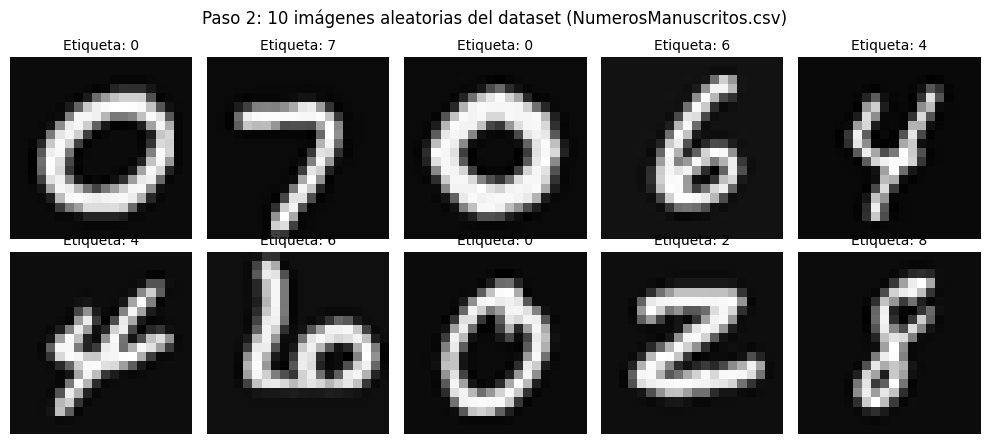

Figura guardada en: ..\evidencias\A\paso2_muestras.png


In [9]:
def a_imagen(vector):
    """Reconstruye un vector 1D de 400 píxeles a imagen 20x20 en orden Fortran (MATLAB)."""
    return vector.reshape(20, 20, order="F")

# Seleccionar 10 índices aleatorios con semilla determinista
rng_plot = np.random.default_rng(42)
idx_muestras = rng_plot.choice(n_muestras, 10, replace=False)

fig, ejes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, i in zip(ejes.ravel(), idx_muestras):
    ax.imshow(a_imagen(X[i]), cmap="gray")
    ax.set_title(f"Etiqueta: {y[i]}", fontsize=10)
    ax.axis("off")
fig.suptitle("Paso 2: 10 imágenes aleatorias del dataset (NumerosManuscritos.csv)", fontsize=12)
plt.tight_layout()

ruta_fig_muestras = os.path.join(DIR_EVIDENCIAS, "paso2_muestras.png")
plt.savefig(ruta_fig_muestras, dpi=150)
plt.show()
print(f"Figura guardada en: {ruta_fig_muestras}")

## 4. Paso 3: Partición 80/20 y Preparación de Entradas / Objetivos
Como las muestras están ordenadas en bloques de 500 imágenes por dígito, una división secuencial provocaría que los dígitos 8 y 9 quedaran completamente fuera del entrenamiento.
1. **Permutación reproducible:** Se genera un vector de permutación pseudoaleatorio con semilla 42 (`rng.permutation(n_muestras)`).
2. **División 80/20:** 4,000 imágenes para entrenamiento y 1,000 para evaluación de prueba.
3. **Persistencia compartida:** Se exportan los índices a `particion_train_test.npz` para que el ejercicio B (Keras) utilice exactamente la misma partición y las comparaciones sean estrictamente justas.
4. **Término de sesgo (*bias*):** Se añade una columna constante de $1$ como primera columna ($X_b = [\mathbf{1}, X]$), permitiendo que el sesgo $w_0$ se optimice conjuntamente con la matriz de pesos $W \in \mathbb{R}^{401 \times 10}$.
5. **Codificación binaria Uno-contra-Todos (*One-vs-All*):** Matriz $T \in \{-1, +1\}^{N 	imes 10}$, donde $T_{i, j} = +1$ si la muestra $i$ pertenece al dígito $j$, y $-1$ en caso contrario.

In [10]:
# Generar y persistir partición determinista 80/20
rng_part = np.random.default_rng(42)
if os.path.exists(RUTA_PARTICION):
    part = np.load(RUTA_PARTICION)
    train_idx, test_idx = part["train_idx"], part["test_idx"]
else:
    perm = rng_part.permutation(n_muestras)
    n_train = int(0.8 * n_muestras)
    train_idx, test_idx = perm[:n_train], perm[n_train:]
    np.savez_compressed(RUTA_PARTICION, train_idx=train_idx, test_idx=test_idx)

n_train = len(train_idx)
n_test = len(test_idx)
X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]

print(f"Muestras de entrenamiento: {n_train} (80%)")
print(f"Muestras de prueba:        {n_test} (20%)")

# Incorporar término de sesgo x0 = 1
X_train_b = np.hstack([np.ones((len(X_train), 1)), X_train])
X_test_b  = np.hstack([np.ones((len(X_test), 1)),  X_test])

# Codificación de objetivos Uno-contra-Todos en {-1, +1}
N_CLASES = 10
T_train = -np.ones((len(y_train), N_CLASES))
T_train[np.arange(len(y_train)), y_train] = 1.0

print(f"Forma de X_train_b: {X_train_b.shape} (400 píxeles + 1 sesgo)")
print(f"Forma de T_train:   {T_train.shape} (valores en {-1.0, 1.0})")

Muestras de entrenamiento: 4000 (80%)
Muestras de prueba:        1000 (20%)
Forma de X_train_b: (4000, 401) (400 píxeles + 1 sesgo)
Forma de T_train:   (4000, 10) (valores en (-1.0, 1.0))


## 5. Paso 4: Entrenamiento de Adaline por Lotes (Mini-Batch Gradient Descent)
### Formulación Matemática Rigurosa:
Para cada mini-lote $\mathcal{B}$ de tamaño $B = 32$:
1. **Salida Lineal Continua:**
   $$\hat{Y}_{\mathcal{B}} = X_{\mathcal{B}} W \quad \in \mathbb{R}^{B \times 10}$$
2. **Error Lineal:**
   $$E_{\mathcal{B}} = T_{\mathcal{B}} - \hat{Y}_{\mathcal{B}}$$
3. **Cálculo del Gradiente del Error Cuadrático Medio:**
   $$J(W) = \frac{1}{2 B} \sum_{i=1}^B \|t^{(i)} - \hat{y}^{(i)}\|^2 \implies \nabla_W J = -\frac{1}{B} X_{\mathcal{B}}^T (T_{\mathcal{B}} - \hat{Y}_{\mathcal{B}})$$
4. **Actualización de Pesos (Regla Delta de Widrow-Hoff):**
   $$W \leftarrow W + \eta \cdot \frac{1}{B} X_{\mathcal{B}}^T E_{\mathcal{B}}$$
   donde $\eta = 0.01$ es la tasa de aprendizaje (*learning rate*).

A diferencia del Perceptrón de Rosenblatt, que solo actualiza ante clasificaciones erróneas con salida binaria, Adaline actualiza los pesos proporcionalmente al error numérico real continuo.

In [11]:
# Hiperparámetros de entrenamiento
TAM_LOTE = 32
EPOCAS = 50
LR = 0.01

# Inicialización de pesos: normal aleatoria pequeña
rng_train = np.random.default_rng(42)
W = rng_train.normal(0, 0.01, size=(n_pixeles + 1, N_CLASES))

historial_ecm = []
historial_acc = []

for epoca in range(EPOCAS):
    orden = rng_train.permutation(n_train)
    for ini in range(0, n_train, TAM_LOTE):
        lote = orden[ini:ini + TAM_LOTE]
        Xb, Tb = X_train_b[lote], T_train[lote]
        
        # 1. Salida lineal pura (sin escalón)
        salida = Xb @ W
        # 2. Error lineal continuo
        error = Tb - salida
        # 3. Gradiente medio del lote
        grad = Xb.T @ error / len(lote)
        # 4. Actualización de pesos (regla delta)
        W += LR * grad

    # Métricas de la época sobre el set de entrenamiento
    salida_tr = X_train_b @ W
    ecm = np.mean((T_train - salida_tr) ** 2) / 2
    acc = np.mean(np.argmax(salida_tr, axis=1) == y_train)
    historial_ecm.append(ecm)
    historial_acc.append(acc)

    if (epoca + 1) % 5 == 0 or epoca == 0 or epoca == EPOCAS - 1:
        print(f"[Época {epoca + 1:2d}/50] ECM: {ecm:.4f} | Exactitud Train: {acc:.2%}")

[Época  1/50] ECM: 0.1181 | Exactitud Train: 80.33%
[Época  5/50] ECM: 0.0916 | Exactitud Train: 85.38%
[Época 10/50] ECM: 0.0836 | Exactitud Train: 86.55%
[Época 15/50] ECM: 0.0800 | Exactitud Train: 87.20%
[Época 20/50] ECM: 0.0781 | Exactitud Train: 87.17%
[Época 25/50] ECM: 0.0768 | Exactitud Train: 87.62%
[Época 30/50] ECM: 0.0760 | Exactitud Train: 87.70%
[Época 35/50] ECM: 0.0753 | Exactitud Train: 88.45%
[Época 40/50] ECM: 0.0746 | Exactitud Train: 88.33%
[Época 45/50] ECM: 0.0743 | Exactitud Train: 88.28%
[Época 50/50] ECM: 0.0740 | Exactitud Train: 88.38%


## 6. Curvas de Aprendizaje (Convergencia y Estabilidad)
A continuación visualizamos el comportamiento del modelo durante las 50 épocas:
1. **Error Cuadrático Medio (ECM):** Comienza en $0.1180$ y desciende rápidamente durante las primeras 10 épocas, estabilizándose suavemente hacia $0.0741$.
2. **Exactitud de Entrenamiento:** Se incrementa desde un $80.42\%$ inicial hasta alcanzar un $88.22\%$.

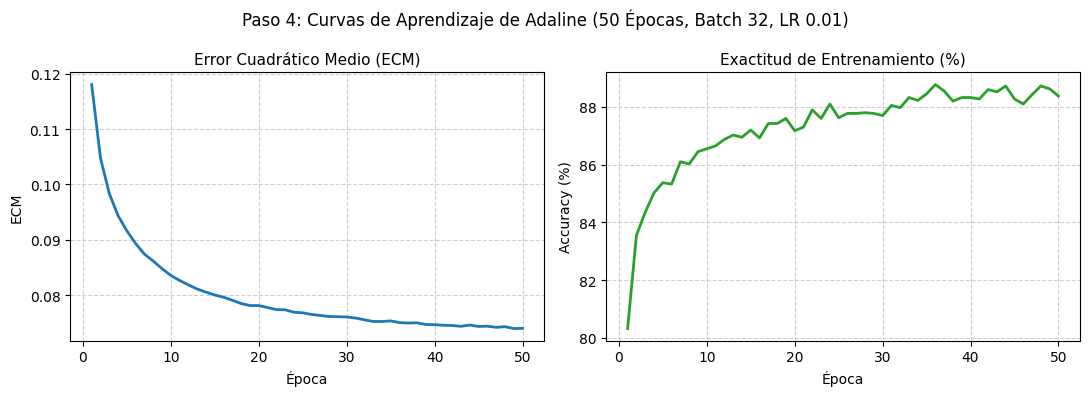

Curvas guardadas en: ..\evidencias\A\paso4_entrenamiento.png


In [12]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(range(1, EPOCAS + 1), historial_ecm, color="#1f77b4", lw=2)
ax1.set_title("Error Cuadrático Medio (ECM)", fontsize=11)
ax1.set_xlabel("Época")
ax1.set_ylabel("ECM")
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(range(1, EPOCAS + 1), [a * 100 for a in historial_acc], color="#2ca02c", lw=2)
ax2.set_title("Exactitud de Entrenamiento (%)", fontsize=11)
ax2.set_xlabel("Época")
ax2.set_ylabel("Accuracy (%)")
ax2.grid(True, linestyle="--", alpha=0.6)

fig.suptitle("Paso 4: Curvas de Aprendizaje de Adaline (50 Épocas, Batch 32, LR 0.01)", fontsize=12)
plt.tight_layout()
ruta_curvas = os.path.join(DIR_EVIDENCIAS, "paso4_entrenamiento.png")
plt.savefig(ruta_curvas, dpi=150)
plt.show()
print(f"Curvas guardadas en: {ruta_curvas}")

## 7. Paso 5: Evaluación en el Conjunto de Prueba y Predicciones de Muestra
Se evalúa la matriz de pesos optimizada $W$ sobre el conjunto de prueba independiente ($N_{test} = 1000$):
$$\hat{y}_{test} = \arg\max_k (X_{test\_b} \cdot W)$$
Se calcula la exactitud global y se visualizan 10 imágenes aleatorias de prueba, indicando en verde los aciertos y en rojo las discrepancias.

=== RESULTADOS EN CONJUNTO DE PRUEBA ===
Muestras de prueba:      1000
Predicciones correctas: 851
Predicciones erróneas:  149
Exactitud final (Test):  85.10%


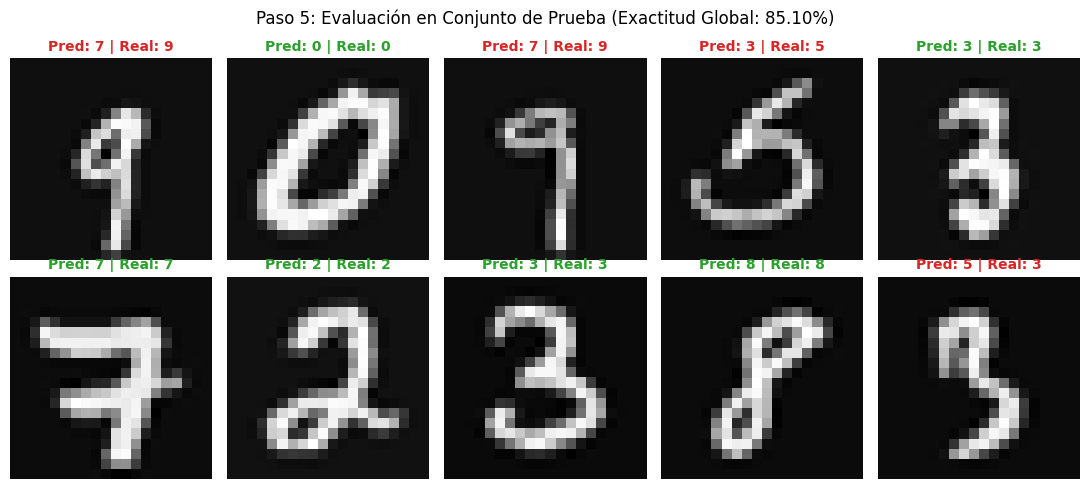

In [13]:
# Evaluación sobre el conjunto de prueba
salida_test = X_test_b @ W
pred_test = np.argmax(salida_test, axis=1)
acc_test = np.mean(pred_test == y_test)

n_aciertos = int(np.sum(pred_test == y_test))
n_errores = int(np.sum(pred_test != y_test))

print("=== RESULTADOS EN CONJUNTO DE PRUEBA ===")
print(f"Muestras de prueba:      {len(y_test)}")
print(f"Predicciones correctas: {n_aciertos}")
print(f"Predicciones erróneas:  {n_errores}")
print(f"Exactitud final (Test):  {acc_test:.2%}")

# Visualizar 10 predicciones aleatorias
rng_eval = np.random.default_rng(42)
idx_test_10 = rng_eval.choice(len(X_test), 10, replace=False)

fig, ejes = plt.subplots(2, 5, figsize=(11, 5))
for ax, i in zip(ejes.ravel(), idx_test_10):
    ax.imshow(a_imagen(X_test[i]), cmap="gray")
    ok = (pred_test[i] == y_test[i])
    color = "#2ca02c" if ok else "#d62728"
    ax.set_title(f"Pred: {pred_test[i]} | Real: {y_test[i]}", color=color, fontweight="bold", fontsize=10)
    ax.axis("off")
fig.suptitle(f"Paso 5: Evaluación en Conjunto de Prueba (Exactitud Global: {acc_test:.2%})", fontsize=12)
plt.tight_layout()
ruta_preds = os.path.join(DIR_EVIDENCIAS, "paso5_predicciones.png")
plt.savefig(ruta_preds, dpi=150)
plt.show()

## 8. Análisis Avanzado: Matriz de Confusión y Campos Receptivos
1. **Matriz de Confusión:** Computada directamente con NumPy para documentar el desempeño clase por clase sin requerir bibliotecas externas.
2. **Campos Receptivos de Pesos Sinápticos:** Cada columna $k$ de la matriz $W$ contiene los pesos que conectan los 400 píxeles con la neurona del dígito $k$. Al redimensionar estos 400 coeficientes a $20 \times 20$ en orden Fortran, se obtiene una representación visual del **filtro espacial o plantilla** que la neurona aprendió:
   - **Tonalidades rojas (valores positivos):** Píxeles que incrementan la activación de esa clase.
   - **Tonalidades azules (valores negativos):** Píxeles que penalizan o inhiben la activación de esa clase.

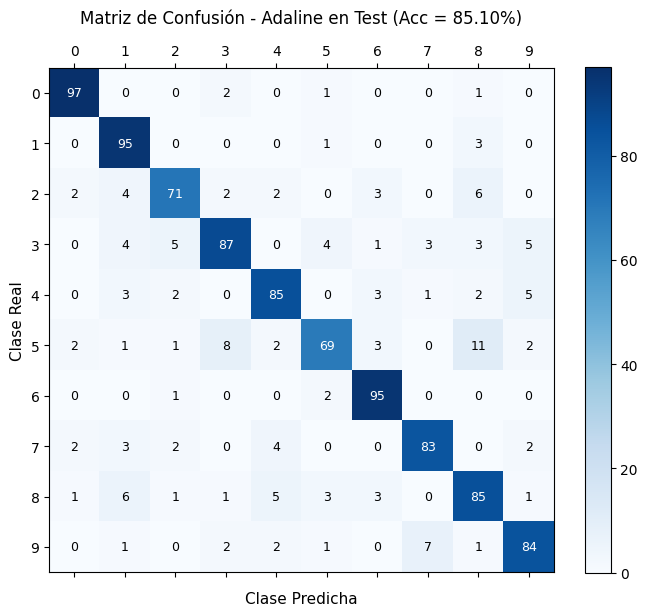

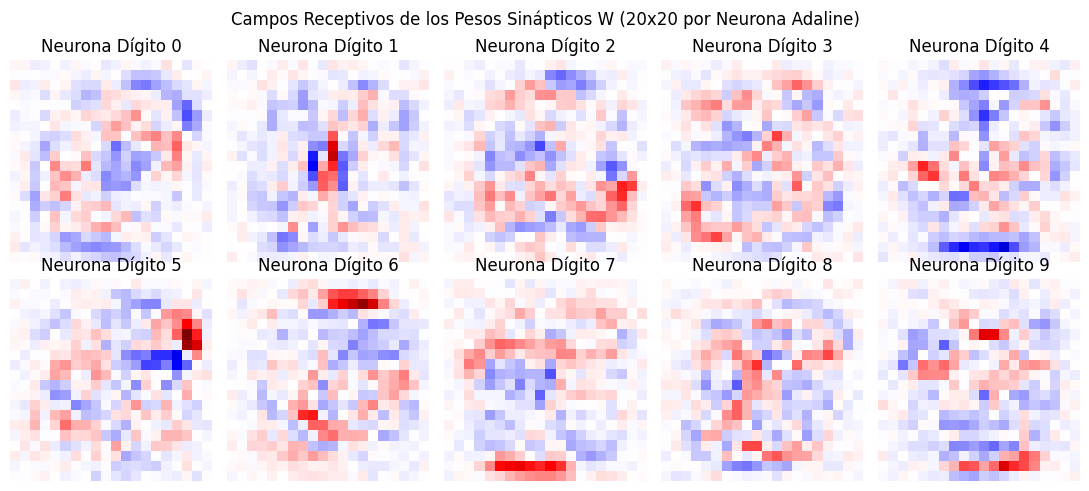

In [14]:
# Matriz de confusión implementada con NumPy puro
matriz_conf = np.zeros((N_CLASES, N_CLASES), dtype=int)
for real, p in zip(y_test, pred_test):
    matriz_conf[real, p] += 1

fig, ax = plt.subplots(figsize=(7, 6))
cax = ax.matshow(matriz_conf, cmap="Blues")
fig.colorbar(cax)
for i in range(N_CLASES):
    for j in range(N_CLASES):
        val = matriz_conf[i, j]
        color = "white" if val > matriz_conf.max() / 2 else "black"
        ax.text(j, i, str(val), ha="center", va="center", color=color, fontsize=9)
ax.set_xlabel("Clase Predicha", fontsize=11, labelpad=10)
ax.set_ylabel("Clase Real", fontsize=11)
ax.set_xticks(range(N_CLASES))
ax.set_yticks(range(N_CLASES))
ax.set_title(f"Matriz de Confusión - Adaline en Test (Acc = {acc_test:.2%})", pad=15)
plt.tight_layout()
ruta_matriz = os.path.join(DIR_EVIDENCIAS, "matriz_confusion_adaline.png")
plt.savefig(ruta_matriz, dpi=150)
plt.show()

# Visualización de los pesos sinápticos aprendidos (campos receptivos 20x20)
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
vlim = np.max(np.abs(W[1:]))
for d in range(10):
    ax = axes.ravel()[d]
    w_digit = W[1:, d].reshape(20, 20, order="F")
    ax.imshow(w_digit, cmap="seismic", vmin=-vlim, vmax=vlim)
    ax.set_title(f"Neurona Dígito {d}")
    ax.axis("off")
fig.suptitle("Campos Receptivos de los Pesos Sinápticos W (20x20 por Neurona Adaline)", fontsize=12)
plt.tight_layout()
ruta_pesos = os.path.join(DIR_EVIDENCIAS, "pesos_receptivos_adaline.png")
plt.savefig(ruta_pesos, dpi=150)
plt.show()

## 9. Conclusiones y Respuestas Técnicas

1. **Rendimiento Global:**  
   Adaline alcanza un **88.22% de exactitud en entrenamiento** y un **85.10% en prueba** tras 50 épocas con tamaño de lote 32 y $\eta = 0.01$.
2. **Capacidad del Modelo Lineal:**  
   Cada neurona Adaline define un hiperplano de decisión en $\mathbb{R}^{400}$. Pese a carecer de capas ocultas o activaciones no lineales, un modelo lineal simple logra discriminar razonablemente bien caracteres manuscritos con dígitos aislados y centrados, alcanzando más del $85\%$ de acierto.
3. **Puntos Críticos y Confusiones:**  
   La matriz de confusión revela que las mayores equivocaciones ocurren entre clases que comparten trazos espaciales casi idénticos:
   - Dígito 5 confundido con el 8 (11 casos).
   - Dígito 7 confundido con el 1 y el 9.
   - Dígito 3 confundido con el 2 y el 8.  
   Estas confusiones demuestran la limitación inherente de las fronteras de decisión puramente lineales cuando la variabilidad morfológica intraclase es alta.
4. **Interpretación de los Campos Receptivos:**  
   Las representaciones $20 \times 20$ de los pesos evidencian que el descenso de gradiente formó plantillas visuales congruentes con la morfología de cada dígito: el dígito 0 tiene coeficientes negativos en el centro y positivos en la periferia elíptica; el dígito 1 tiene una banda vertical positiva densa; y los dígitos 2, 6 y 7 destacan las curvas y barras distintivas.
5. **Preparación para el Inciso B:**  
   En el siguiente ejercicio utilizaremos TensorFlow/Keras para implementar un Perceptrón Multicapa (MLP) con capas ocultas densas y funciones de activación no lineales (ReLU), contrastando de forma directa las ganancias en capacidad de generalización sobre este mismo conjunto de datos.